# P1 데이터 정제 흐름

`cleaning.py`와 `validate.py`를 사용해 원본 진단 → 컬럼명 통일 → 중복 제거 → 날짜·등급 정규화 → 센티널 처리 → 결측 대체 → 품질 검증 → 시각화 순서로 진행합니다.

## 1. 환경과 원본 데이터

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'module1_preprocessing/cleaning.py').exists()), None)
if ROOT is None:
    candidate = cwd / 'Metal_Recovery_Optimizer'
    if (candidate / 'module1_preprocessing/cleaning.py').exists():
        ROOT = candidate
if ROOT is None:
    raise FileNotFoundError('Metal_Recovery_Optimizer 또는 notebooks 폴더에서 실행하세요.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from module1_preprocessing import cleaning as p1
from module1_preprocessing import validate as quality

# validate 모듈의 폰트 설정을 현재 환경에 맞게 덮어씁니다.
from matplotlib import font_manager
fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic'] if f in fonts), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False

RAW_PATH = ROOT / 'data/raw' / '영풍그룹_금속회수율최적화_RawMaterialData_학생배포용.xlsx'
if not RAW_PATH.is_file():
    raise FileNotFoundError(
        f'원본 엑셀을 프로젝트의 data/raw/{RAW_PATH.name}에 넣고 다시 실행하세요.'
    )
raw = p1.load_raw(str(RAW_PATH))
dictionary = pd.read_excel(RAW_PATH, sheet_name=quality.DICT_SHEET)
print('원본:', RAW_PATH.relative_to(ROOT))
print('크기:', raw.shape)
display(raw.head(), dictionary)

history = []
def snapshot(name, frame):
    history.append({'단계': name, '행': len(frame), '열': frame.shape[1],
                    '결측 셀': int(frame.isna().sum().sum())})
snapshot('원본', raw)

원본: data/raw/영풍그룹_금속회수율최적화_RawMaterialData_학생배포용.xlsx
크기: (424, 16)


,배치ID,분석일자,원료등급,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct,원료투입량_kg,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct
0,BP-2025-0001,2025-01-02,C,13.30,NaN,2.93,13.66,1.71,NaN,2.87,121.1,1107,88.8,1.33,85.87,77.34
1,BP-2025-0002,2025/01/02,B,12.17,6.98,4.25,10.49,1.90,2.04,3.43,159.1,1118,55.6,6.32,85.65,78.45
2,BP-2025-0003,03.01.2025,C,11.83,6.76,3.06,10.33,2.97,1.87,3.52,128.3,1069,84.9,NaN,87.40,79.18
3,BP-2025-0004,20250103,B,17.10,9.21,4.83,8.51,2.00,0.98,2.83,98.5,1455,77.7,7.98,98.79,88.33
4,BP-2025-0005,"Jan 03, 2025",A급,23.67,NaN,5.06,8.09,0.64,NaN,0.94,143.4,959,68.2,3.44,87.06,83.92


,컬럼명,설명,단위,정상 범위/값
0,배치ID,원료 배치(LOT) 고유번호,-,BP-2025-XXXX
1,분석일자,랩실 성분 분석 일자,날짜,2025년
2,원료등급,"원료 품질 등급 (A=고니켈·저불순물, C=저니켈·고불순물)",-,A / B / C
3,Ni_함량_pct,니켈 함량 (회수 목표 금속),wt%,8 ~ 30
4,Co_함량_pct,코발트 함량 (회수 목표 금속),wt%,2 ~ 15
5,Li_함량_pct,리튬 함량,wt%,2 ~ 6
6,Mn_함량_pct,망간 함량,wt%,5 ~ 16
7,Cu_불순물_pct,구리 불순물,wt%,0.3 ~ 6
8,Fe_불순물_pct,철 불순물,wt%,0.2 ~ 6
9,Al_불순물_pct,알루미늄 불순물,wt%,0.5 ~ 7


## 2. 원본 품질 진단
결측 수, 자료형, 완전 동일 중복을 계산

In [2]:
display(pd.DataFrame({'자료형': raw.dtypes.astype(str), '결측 수': raw.isna().sum()}))
print('완전 동일 중복:', int(raw.duplicated().sum()))
display(raw.loc[raw.duplicated(keep=False)].sort_values('배치ID'))

,자료형,결측 수
배치ID,str,0
분석일자,str,22
원료등급,str,0
Ni_함량_pct,float64,30
Co_함량_pct,float64,31
Li_함량_pct,float64,34
Mn_함량_pct,float64,25
Cu_불순물_pct,float64,28
Fe_불순물_pct,float64,35
Al_불순물_pct,float64,26


완전 동일 중복: 4


,배치ID,분석일자,원료등급,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct,원료투입량_kg,황산투입량_L,침출온도_C,침출시간_hr,Ni_회수율_pct,Co_회수율_pct
17,BP-2025-0018,01/13/25,A,23.52,13.11,4.23,11.18,0.84,0.66,1.83,80.9,1177,55.9,NaN,93.34,87.21
422,BP-2025-0018,01/13/25,A,23.52,13.11,4.23,11.18,0.84,0.66,1.83,80.9,1177,55.9,NaN,93.34,87.21
165,BP-2025-0166,20250421,B,17.64,7.41,3.88,9.53,1.23,1.03,2.06,126.9,945,NaN,1.97,81.47,75.32
421,BP-2025-0166,20250421,B,17.64,7.41,3.88,9.53,1.23,1.03,2.06,126.9,945,NaN,1.97,81.47,75.32
179,BP-2025-0180,04/28/25,B,13.60,9.13,NaN,15.30,1.25,1.45,3.76,114.4,644,42.2,4.54,75.61,72.69
423,BP-2025-0180,04/28/25,B,13.60,9.13,NaN,15.30,1.25,1.45,3.76,114.4,644,42.2,4.54,75.61,72.69
378,BP-2025-0379,NaN,B,20.49,6.60,3.26,10.86,1.57,0.93,2.19,112.8,1153,52.2,1.39,81.37,77.63
420,BP-2025-0379,NaN,B,20.49,6.60,3.26,10.86,1.57,0.93,2.19,112.8,1153,52.2,1.39,81.37,77.63


## 3. 컬럼명 통일과 중복 제거
한글 컬럼을 계약용 영문 이름으로 바꾸고, 모든 값이 동일한 중복만 제거합니다. 같은 ID에 다른 값이 있는 경우는 따로 확인해야 합니다.

In [3]:
display(pd.DataFrame(p1.COLUMN_MAP.items(), columns=['원본 컬럼', '변환 컬럼']))
renamed = p1.normalize_columns(raw)
dedup = p1.drop_duplicate_rows(renamed)
snapshot('중복 제거', dedup)
print(f'{len(raw)}행 → {len(dedup)}행')
print('중복 제거 후 ID 중복:', int(dedup['batch_id'].duplicated().sum()))
assert dedup['batch_id'].notna().all() and dedup['batch_id'].is_unique
display(dedup.head())

,원본 컬럼,변환 컬럼
0,배치ID,batch_id
1,분석일자,analysis_date
2,원료등급,grade
3,Ni_함량_pct,ni_pct
4,Co_함량_pct,co_pct
5,Li_함량_pct,li_pct
6,Mn_함량_pct,mn_pct
7,Cu_불순물_pct,cu_pct
8,Fe_불순물_pct,fe_pct
9,Al_불순물_pct,al_pct


424행 → 420행
중복 제거 후 ID 중복: 0


,batch_id,analysis_date,grade,ni_pct,co_pct,li_pct,mn_pct,cu_pct,fe_pct,al_pct,feed_kg,acid_l,temp_c,time_hr,ni_recovery_pct,co_recovery_pct
0,BP-2025-0001,2025-01-02,C,13.30,NaN,2.93,13.66,1.71,NaN,2.87,121.1,1107,88.8,1.33,85.87,77.34
1,BP-2025-0002,2025/01/02,B,12.17,6.98,4.25,10.49,1.90,2.04,3.43,159.1,1118,55.6,6.32,85.65,78.45
2,BP-2025-0003,03.01.2025,C,11.83,6.76,3.06,10.33,2.97,1.87,3.52,128.3,1069,84.9,NaN,87.40,79.18
3,BP-2025-0004,20250103,B,17.10,9.21,4.83,8.51,2.00,0.98,2.83,98.5,1455,77.7,7.98,98.79,88.33
4,BP-2025-0005,"Jan 03, 2025",A급,23.67,NaN,5.06,8.09,0.64,NaN,0.94,143.4,959,68.2,3.44,87.06,83.92


## 4. 날짜와 원료등급 정규화
날짜는 P1의 명시적 6종 포맷으로 해석합니다. `03.01.2025`는 일·월·년, `01/03/25`는 월·일·년입니다.
등급은 공백, 소문자, `급` 접미사를 정리해 A/B/C로 통일합니다. 날짜 결측은 그대로 유지합니다.

In [4]:
normalized = dedup.copy()
normalized['analysis_date'] = p1.parse_dates(dedup['analysis_date'])
normalized['grade'] = p1.normalize_grade(dedup['grade'])
display(pd.DataFrame({'원본 날짜': dedup['analysis_date'], '변환 날짜': normalized['analysis_date'],
                      '원본 등급': dedup['grade'], '변환 등급': normalized['grade']}).head(20))
parse_fail = dedup['analysis_date'].notna() & normalized['analysis_date'].isna()
print('원래 날짜 결측:', int(dedup['analysis_date'].isna().sum()))
print('값이 있었지만 변환 실패:', int(parse_fail.sum()))
display(dedup.loc[parse_fail, ['batch_id', 'analysis_date']])
display(normalized['grade'].value_counts().rename('행 수').to_frame())
snapshot('날짜·등급 정규화', normalized)

,원본 날짜,변환 날짜,원본 등급,변환 등급
0,2025-01-02,2025-01-02,C,C
1,2025/01/02,2025-01-02,B,B
2,03.01.2025,2025-01-03,C,C
3,20250103,2025-01-03,B,B
4,"Jan 03, 2025",2025-01-03,A급,A
5,01/03/25,2025-01-03,C,C
6,2025-01-05,2025-01-05,C,C
7,2025/01/05,2025-01-05,C급,C
8,06.01.2025,2025-01-06,A,A
9,20250106,2025-01-06,B,B


원래 날짜 결측: 21
값이 있었지만 변환 실패: 0


,batch_id,analysis_date


,행 수
grade,
B,162
A,148
C,110


## 5. 센티널을 결측으로 변환
Ni 함량 999, 황산 15000, 온도 -5, 시간 0을 결측으로 바꿉니다.
행은 유지하고 그 외 데이터사전 범위 밖 경계값도 유지합니다.
처리 건수와 처리 전후 값을 확인합니다.

In [5]:
sentinel_hits = pd.DataFrame({col: normalized[col].isin(values) for col, values in p1.SENTINELS.items()})
display(sentinel_hits.sum().rename('처리 셀 수').to_frame())
affected = sentinel_hits.any(axis=1)
masked = p1.mask_sentinels(normalized).copy()  # sentinel_* 플래그 유지
display(normalized.loc[affected, ['batch_id'] + list(p1.SENTINELS)])
display(masked.loc[affected, ['batch_id'] + list(p1.SENTINELS)])
snapshot('센티널 처리', masked)

,처리 셀 수
ni_pct,3
acid_l,2
temp_c,2
time_hr,2


,batch_id,ni_pct,acid_l,temp_c,time_hr
10,BP-2025-0011,999.00,705,66.3,2.71
24,BP-2025-0025,999.00,757,48.6,3.08
46,BP-2025-0047,18.71,1334,NaN,0.00
98,BP-2025-0099,22.51,503,-5.0,5.59
102,BP-2025-0103,24.88,15000,93.8,NaN
123,BP-2025-0124,17.71,15000,86.3,6.70
208,BP-2025-0209,999.00,1189,NaN,8.00
230,BP-2025-0231,27.98,1112,86.8,0.00
337,BP-2025-0338,20.22,1119,-5.0,5.21


,batch_id,ni_pct,acid_l,temp_c,time_hr
10,BP-2025-0011,NaN,705.0,66.3,2.71
24,BP-2025-0025,NaN,757.0,48.6,3.08
46,BP-2025-0047,18.71,1334.0,NaN,NaN
98,BP-2025-0099,22.51,503.0,NaN,5.59
102,BP-2025-0103,24.88,NaN,93.8,NaN
123,BP-2025-0124,17.71,NaN,86.3,6.70
208,BP-2025-0209,NaN,1189.0,NaN,8.00
230,BP-2025-0231,27.98,1112.0,86.8,NaN
337,BP-2025-0338,20.22,1119.0,NaN,5.21


## 6. 등급별 중앙값 대치
기존 P1 기본값인 `grade_median`을 실행합니다. 같은 등급의 중앙값을 사용하고, 해당 등급에서 계산할 수 없으면 전체 중앙값으로 보정합니다.

**모델링 연결 시 검토:** 기존 `clean()`은 전달된 전체 데이터에서 중앙값을 계산합니다. 예측 성능 평가에서는 데이터를 먼저 분할하고 학습 데이터에서만 대치 기준을 계산해야 합니다. 아래 결과는 기존 P1 흐름을 재현한 정제 결과입니다.

In [6]:
display(masked.groupby('grade', observed=True)[p1.FEATURE_COLS].median())
imputed = p1.impute(masked, strategy='grade_median').copy()  # imputed_* 플래그 유지
display(pd.DataFrame({'대치 전 결측': masked[p1.FEATURE_COLS + p1.TARGET_COLS].isna().sum(),
                      '대치 후 결측': imputed[p1.FEATURE_COLS + p1.TARGET_COLS].isna().sum()}))
example_col = 'ni_pct'
missing = masked[example_col].isna()
display(pd.DataFrame({'배치': masked.loc[missing, 'batch_id'], '등급': masked.loc[missing, 'grade'],
                      '대치 전': masked.loc[missing, example_col], '대치 후': imputed.loc[missing, example_col]}).head(15))
snapshot('등급별 중앙값 대치', imputed)

,ni_pct,co_pct,li_pct,mn_pct,cu_pct,fe_pct,al_pct,feed_kg,acid_l,temp_c,time_hr
grade,,,,,,,,,,,
A,24.265,10.96,4.60,9.005,0.73,0.600,1.20,145.75,928.0,66.7,4.055
B,18.215,7.71,3.80,10.860,1.83,1.525,2.62,146.60,917.0,66.2,4.090
C,12.230,5.02,2.95,12.185,3.53,3.140,4.47,137.60,932.5,67.3,4.260


,대치 전 결측,대치 후 결측
ni_pct,33,0
co_pct,31,0
li_pct,33,0
mn_pct,25,0
cu_pct,28,0
fe_pct,35,0
al_pct,26,0
feed_kg,0,0
acid_l,2,0
temp_c,40,0


,배치,등급,대치 전,대치 후
10,BP-2025-0011,B,NaN,18.215
12,BP-2025-0013,B,NaN,18.215
21,BP-2025-0022,B,NaN,18.215
24,BP-2025-0025,C,NaN,12.230
34,BP-2025-0035,B,NaN,18.215
36,BP-2025-0037,A,NaN,24.265
43,BP-2025-0044,A,NaN,24.265
52,BP-2025-0053,C,NaN,12.230
59,BP-2025-0060,A,NaN,24.265
90,BP-2025-0091,A,NaN,24.265


## 7. 기존 파이프라인과 일치하는지 검증
단계별 결과를 기존 `clean()`의 컬럼 순서로 정렬하고 값·자료형까지 비교합니다. 식별자, 등급, 날짜 자료형, 모델 입력 결측과 유한값도 확인합니다.

In [7]:
reference = p1.clean(raw)  # 플래그 포함 33열 전체와 비교
cleaned = imputed.loc[:, reference.columns].copy()
pd.testing.assert_frame_equal(cleaned, reference)
assert cleaned['batch_id'].is_unique
assert cleaned['grade'].isin(['A', 'B', 'C']).all()
assert pd.api.types.is_datetime64_any_dtype(cleaned['analysis_date'])
assert cleaned[p1.FEATURE_COLS + p1.TARGET_COLS].notna().all().all()
assert np.isfinite(cleaned[p1.FEATURE_COLS + p1.TARGET_COLS].to_numpy(dtype=float)).all()
assert cleaned[p1.TARGET_COLS].ge(0).all().all() and cleaned[p1.TARGET_COLS].le(100).all().all()
print('단계별 결과와 clean(raw)가 동일합니다. 기본 정합성 검증 통과.')
display(pd.DataFrame(history))

단계별 결과와 clean(raw)가 동일합니다. 기본 정합성 검증 통과.


,단계,행,열,결측 셀
0,원본,424,16,307
1,중복 제거,420,16,303
2,날짜·등급 정규화,420,16,303
3,센티널 처리,420,20,312
4,등급별 중앙값 대치,420,33,21


## 8. 데이터사전 범위 위반 확인
센티널과 경계값을 구분합니다. 기존 P1은 범위 밖 경계값을 유지하고 보고하므로, 아래 위반 목록은 실패 판정이 아니라 추가 검토 대상입니다. 대치된 값이 범위를 벗어나는지도 함께 확인합니다.

In [8]:
ranges = quality.load_valid_ranges(str(RAW_PATH))
range_summary, range_detail = quality.range_violation_report(cleaned, ranges)
display(range_summary, range_detail)
print('범위 위반 셀 수:', int(range_summary['위반 건수'].sum()))

,컬럼,정상범위,위반 건수
0,ni_pct,8 ~ 30,8
1,co_pct,2 ~ 15,0
2,li_pct,2 ~ 6,5
3,mn_pct,5 ~ 16,4
4,cu_pct,0.3 ~ 6,14
5,fe_pct,0.2 ~ 6,10
6,al_pct,0.5 ~ 7,13
7,feed_kg,80 ~ 200,0
8,acid_l,400 ~ 1500,0
9,temp_c,40 ~ 95,0


,batch_id,컬럼,값,정상범위,대치값?
0,BP-2025-0117,ni_pct,7.47,8 ~ 30,False
1,BP-2025-0202,ni_pct,7.07,8 ~ 30,False
2,BP-2025-0219,ni_pct,7.70,8 ~ 30,False
3,BP-2025-0277,ni_pct,30.92,8 ~ 30,False
4,BP-2025-0281,ni_pct,30.33,8 ~ 30,False
5,BP-2025-0297,ni_pct,6.92,8 ~ 30,False
6,BP-2025-0327,ni_pct,7.61,8 ~ 30,False
7,BP-2025-0392,ni_pct,31.58,8 ~ 30,False
8,BP-2025-0042,li_pct,1.65,2 ~ 6,False
9,BP-2025-0160,li_pct,1.84,2 ~ 6,False


범위 위반 셀 수: 54


## 9. 처리 전후 시각화
중복 제거 후 동일한 행 집합으로 비교합니다. 센티널을 제외한 관측값과 대치 후 값을 비교해 큰 센티널에 의해 축이 왜곡되는 것을 피합니다. 분포 변화만으로 대치 방법의 예측 성능을 판단할 수는 없습니다.

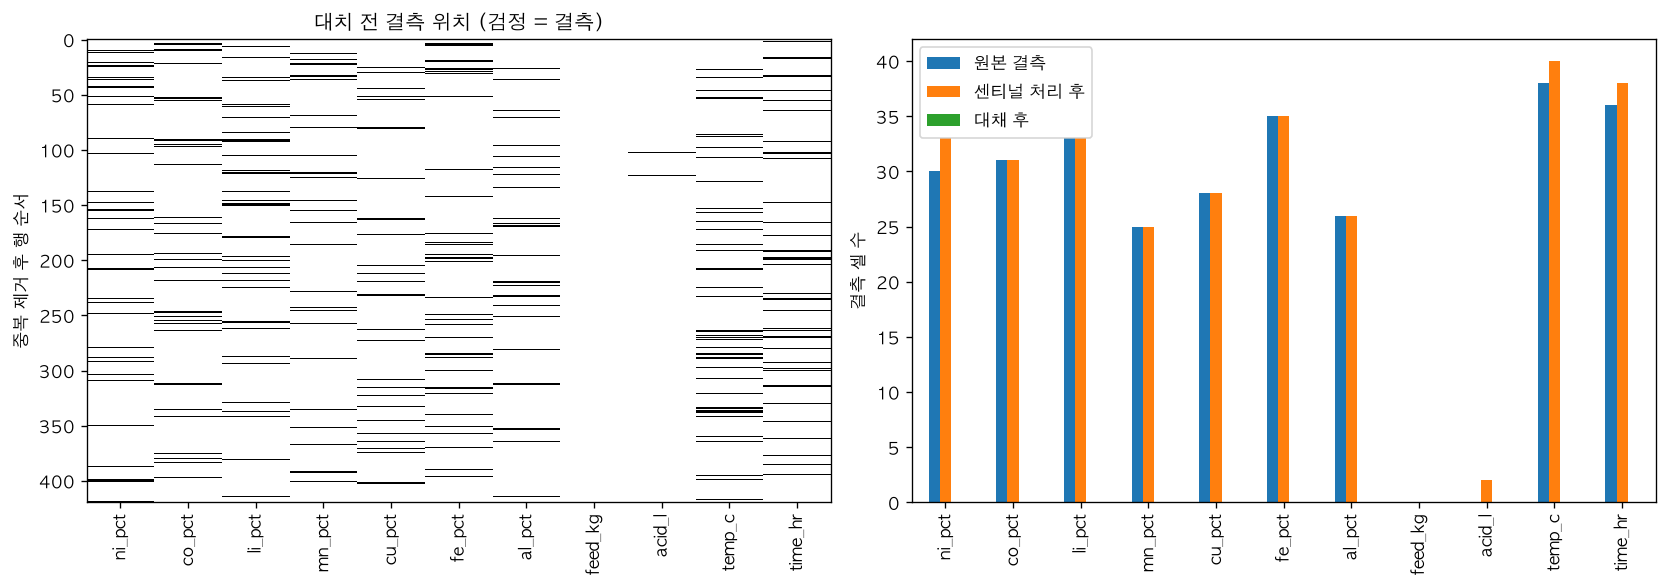

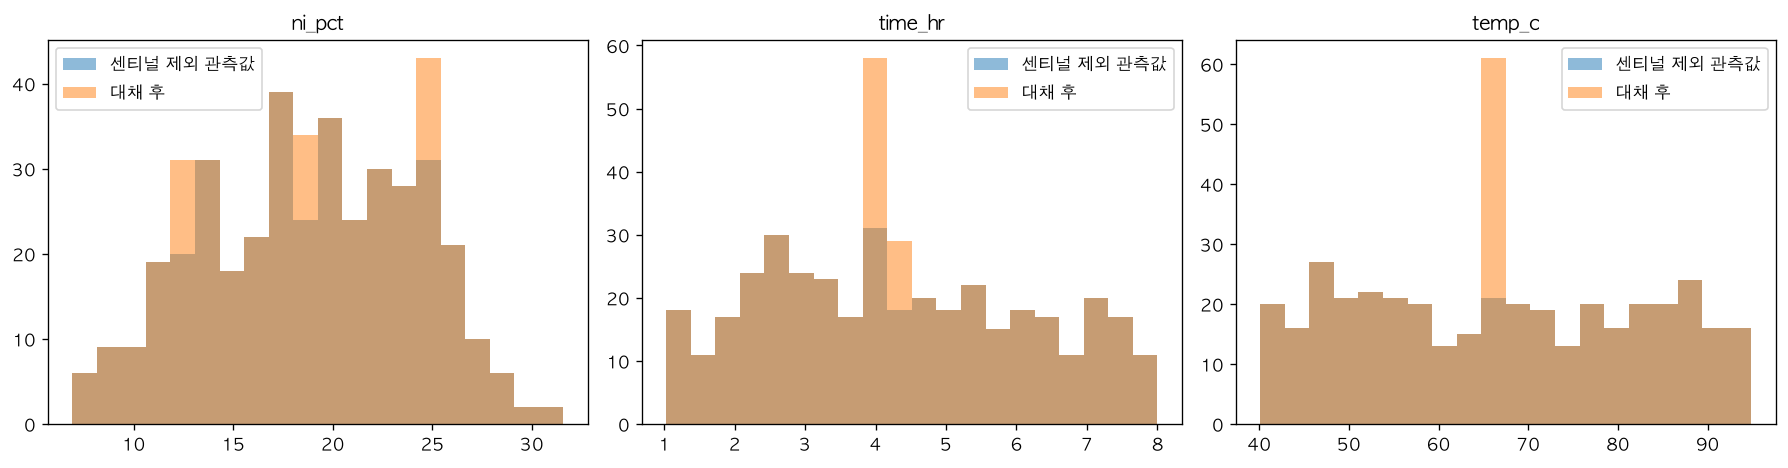

In [9]:
from io import BytesIO
from IPython.display import Image

def show_figure(figure):
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))

missing_before = masked[p1.FEATURE_COLS].isna()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(missing_before.to_numpy(), aspect='auto', cmap='gray_r', interpolation='nearest')
axes[0].set_xticks(range(len(p1.FEATURE_COLS)), p1.FEATURE_COLS, rotation=90)
axes[0].set_title('대치 전 결측 위치 (검정 = 결측)')
axes[0].set_ylabel('중복 제거 후 행 순서')
pd.DataFrame({'원본 결측': dedup[p1.FEATURE_COLS].isna().sum(),
              '센티널 처리 후': masked[p1.FEATURE_COLS].isna().sum(),
              '대채 후': cleaned[p1.FEATURE_COLS].isna().sum()}).plot.bar(ax=axes[1])
axes[1].set_ylabel('결측 셀 수')
fig.tight_layout()
show_figure(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['ni_pct', 'time_hr', 'temp_c']):
    before = masked[col].dropna().to_numpy(dtype=float)
    after = cleaned[col].to_numpy(dtype=float)
    bins = np.histogram_bin_edges(np.concatenate([before, after]), bins=20)
    ax.hist(before, bins=bins, alpha=.5, label='센티널 제외 관측값')
    ax.hist(after, bins=bins, alpha=.5, label='대채 후')
    ax.set_title(col)
    ax.legend()
fig.tight_layout()
show_figure(fig)
plt.close(fig)

## 10. P2로 전달 및 결과 저장
P2는 `p1_proccessed.csv`의 처리값으로 EDA·파생변수 생성·검증을 수행합니다.
날짜 결측은 시간순 평가에서 보류합니다.

`SAVE_RESULTS=True`로 설정하면 `data/processed/p1_flow_notebook/`에 저장합니다.
- `p1_processed.csv`: 정제 데이터 33열 (원본 16열 + sentinel_/imputed_ 플래그 17열)
- `range_summary.csv`: 정상 범위 위반 요약

In [10]:
SAVE_RESULTS = True
if SAVE_RESULTS:
    output_dir = ROOT / 'data/processed/p1_flow_notebook'
    output_dir.mkdir(parents=True, exist_ok=True)
    cleaned.to_csv(output_dir / 'p1_processed.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
    range_summary.to_csv(output_dir / 'range_summary.csv', index=False, encoding='utf-8-sig')
    print('저장 위치:', output_dir.relative_to(ROOT))
else:
    print('저장하지 않았습니다. cleaned 변수에서 최종 정제본을 확인하세요.')

저장 위치: data/processed/p1_flow_notebook
